# 01 Data Preparation
Load the two sheets of Online Retail II, check their structure, combine and clean them,
and save a cleaned transaction table for the rest of the analysis.

In [1]:
import os
import pandas as pd
print(os.getcwd()) 
print(pd.__version__)

/Users/cheennnn/Documents/McMaster/2026 fall/O712 Data Analytics with Python/group project/O712 Group Project
2.3.3


In [2]:
# Path to the raw data (relative to the project folder)
RAW_FILE = "data/raw/online_retail_II.xlsx"

In [3]:
# Read only the first 5 rows of every sheet to see the sheet names and columns
preview = pd.read_excel(RAW_FILE, sheet_name=None, nrows=5)

print("Number of sheets:", len(preview))
for name, df in preview.items():
    print(name)
    display(df)

Number of sheets: 2
Year 2009-2010


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


Year 2010-2011


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


**Observations from the preview**
- The workbook has 2 sheets, and both appear to have the same 8 columns.
- One row is one product line on one invoice (the same invoice number repeats across rows).
- StockCode contains letters (e.g. 79323P, 85123A), so it is a code, not a number. Invoice is also an identifier.
  Both will be read as text.

In [4]:
# Load both sheets fully.
sheets = pd.read_excel(RAW_FILE, sheet_name=None,
                       dtype={"Invoice": str, "StockCode": str})

In [5]:
# Size and date range of each sheet
for name, df in sheets.items():
    print(name, "| rows:", len(df), "| columns:", df.shape[1],
          "| dates:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

print("Total rows across both sheets:", sum(len(df) for df in sheets.values()))

Year 2009-2010 | rows: 525461 | columns: 8 | dates: 2009-12-01 07:45:00 to 2010-12-09 20:01:00
Year 2010-2011 | rows: 541910 | columns: 8 | dates: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Total rows across both sheets: 1067371


**Observations from loading**
- Year 2009-2010: 525,461 rows; Year 2010-2011: 541,910 rows; 8 columns each (1,067,371 rows in total).
- The date ranges overlap: both sheets cover 2010-12-01 to 2010-12-09. Whether these rows are duplicates must be checked before combining.

In [6]:
# Structure of each sheet: column names, non-missing counts and data types
for name, df in sheets.items():
    print(name)
    df.info()
    print()

Year 2009-2010
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB

Year 2010-2011
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      541910 non-null  object        
 1   StockCode   

In [7]:
# Compare the two sheets' columns and data types
names = list(sheets.keys())
s1, s2 = sheets[names[0]], sheets[names[1]]

print("Same columns in same order:", list(s1.columns) == list(s2.columns))
print("Only in", names[0], ":", set(s1.columns) - set(s2.columns))
print("Only in", names[1], ":", set(s2.columns) - set(s1.columns))
print("Same data types:", list(s1.dtypes) == list(s2.dtypes))

Same columns in same order: True
Only in Year 2009-2010 : set()
Only in Year 2010-2011 : set()
Same data types: True


In [8]:
# Missing values in each column, per sheet
missing = pd.DataFrame({name: df.isnull().sum() for name, df in sheets.items()})
missing

,Year 2009-2010,Year 2010-2011
Invoice,0,0
StockCode,0,0
Description,2928,1454
Quantity,0,0
InvoiceDate,0,0
Price,0,0
Customer ID,107927,135080
Country,0,0


**Observations from the structure check**
- Both sheets have the same 8 columns, in the same order, with the same data types, so they can be combined directly.
- Missing values: Description (2,928 and 1,454 rows) and Customer ID (107,927 and 135,080 rows).
- Customer ID is stored as float64, probably because of the missing values. To be handled later.

In [9]:
# Combine the two sheets into one table.
# Add a "Sheet" column so we can still tell where each row came from.
raw = pd.concat([df.assign(Sheet=name) for name, df in sheets.items()],
                ignore_index=True)

print("Rows after combining:", len(raw))
print("Sum of the two sheets:", sum(len(df) for df in sheets.values()))
print("Columns:", list(raw.columns))

Rows after combining: 1067371
Sum of the two sheets: 1067371
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Sheet']


In [10]:
# Rebuild the expected combined table from the source sheets.
expected = pd.concat(sheets.values(), ignore_index=True)
actual = raw.drop(columns="Sheet")

pd.testing.assert_frame_equal(actual, expected)

# Confirm each row's Sheet label and per-sheet contents.
for sheet_name, sheet_df in sheets.items():
    actual_sheet = raw.loc[raw["Sheet"] == sheet_name, sheet_df.columns].reset_index(drop=True)
    pd.testing.assert_frame_equal(actual_sheet, sheet_df.reset_index(drop=True))

assert len(raw) == sum(len(df) for df in sheets.values()), "Row count changed after combining"

print("Checks passed: combined rows match both source sheets exactly.")

Checks passed: combined rows match both source sheets exactly.


In [11]:
# Date range for each source sheet in the combined table
date_ranges = raw.groupby("Sheet")["InvoiceDate"].agg(["min", "max"])
display(date_ranges)

# The overlap is the later start date through the earlier end date
overlap_start = date_ranges["min"].max()
overlap_end = date_ranges["max"].min()

if overlap_start <= overlap_end:
    print(f"Overlapping period: {overlap_start} to {overlap_end}")
else:
    print("The sheets have no overlapping period.")

,min,max
Sheet,,
Year 2009-2010,2009-12-01 07:45:00,2010-12-09 20:01:00
Year 2010-2011,2010-12-01 08:26:00,2011-12-09 12:50:00


Overlapping period: 2010-12-01 08:26:00 to 2010-12-09 20:01:00


In [12]:
# Extract rows that fall within the shared date range.
overlap_1 = s1.loc[s1["InvoiceDate"].between(overlap_start, overlap_end)].copy()
overlap_2 = s2.loc[s2["InvoiceDate"].between(overlap_start, overlap_end)].copy()

columns = s1.columns.tolist()

# Count exact row values, preserving duplicate occurrences while ignoring row order.
counts_1 = overlap_1.value_counts(subset=columns, dropna=False)
counts_2 = overlap_2.value_counts(subset=columns, dropna=False)

overlap_comparison = (
    pd.concat(
        {"Rows in first sheet": counts_1, "Rows in second sheet": counts_2},
        axis=1
    )
    .fillna(0)
    .astype(int)
)

overlap_comparison["Difference"] = (
    overlap_comparison["Rows in first sheet"]
    - overlap_comparison["Rows in second sheet"]
)

print("Rows in the date overlap:")
print(names[0], ":", len(overlap_1))
print(names[1], ":", len(overlap_2))

print("Are the overlap contents identical?",
      overlap_comparison["Difference"].eq(0).all())

print("Number of rows that differ between the two sheets:",
      overlap_comparison["Difference"].ne(0).sum())

Rows in the date overlap:
Year 2009-2010 : 22523
Year 2010-2011 : 22523
Are the overlap contents identical? True
Number of rows that differ between the two sheets: 0


**Observations from the overlap check**
- Both sheets cover 2010-12-01 08:26 to 2010-12-09 20:01, with 22,523 rows each.
- The overlapping rows are identical in both sheets, including how often each row appears (0 rows differ).
  This period was stored twice, so the copy from the later sheet will be removed.

In [13]:
# Remove rows from the later sheet that fall inside the overlapping period.
# The result is stored in a new table, "combined", so that "raw" stays as the original combined data.
later_sheet = names[1]
earlier_sheet = names[0]

second_copy_mask = (
    (raw["Sheet"] == later_sheet)
    & raw["InvoiceDate"].between(overlap_start, overlap_end)
)

removed_rows = second_copy_mask.sum()
combined = raw.loc[~second_copy_mask].copy()

print("Rows removed:", removed_rows)
print("Rows remaining:", len(combined))

# Check 1: exactly the later sheet's overlap rows were removed
assert removed_rows == len(overlap_2), "Removed rows do not match the overlap"
assert len(combined) == len(raw) - removed_rows, "Row count after removal is wrong"

# Check 2: the kept copy (earlier sheet) of the overlap is still complete
kept = (
    (combined["Sheet"] == earlier_sheet)
    & combined["InvoiceDate"].between(overlap_start, overlap_end)
)
assert kept.sum() == len(overlap_1), "The kept copy of the overlap is incomplete"

print("Checks passed: the later copy was removed and the earlier copy is complete.")

Rows removed: 22523
Rows remaining: 1044848
Checks passed: the later copy was removed and the earlier copy is complete.


In [14]:
# Cleaning log: one entry per step that removes rows
cleaning_log = []
cleaning_log.append({"Step": "Combine the two sheets",
                     "Rows removed": 0, "Rows remaining": len(raw)})
cleaning_log.append({"Step": "Remove the duplicated overlap period (later sheet copy)",
                     "Rows removed": int(removed_rows), "Rows remaining": len(combined)})
pd.DataFrame(cleaning_log)

,Step,Rows removed,Rows remaining
0,Combine the two sheets,0,1067371
1,Remove the duplicated overlap period (later sh...,22523,1044848


## Exact duplicate rows

In [15]:
# Exact duplicate rows in the combined data (comparing the 8 original columns, not "Sheet")
data_cols = list(s1.columns)

involved = combined.duplicated(subset=data_cols, keep=False)        # every row that has an identical twin
extra_copies = combined.duplicated(subset=data_cols, keep="first")  # copies beyond the first occurrence

print("Rows involved in exact duplication:", involved.sum())
print("Extra copies (would be removed if keeping one of each):", extra_copies.sum())

Rows involved in exact duplication: 22813
Extra copies (would be removed if keeping one of each): 11812


In [16]:
# Look at some duplicated rows, sorted so identical rows sit next to each other
combined[involved].sort_values(data_cols).head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sheet
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,Year 2009-2010
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,Year 2009-2010
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,Year 2009-2010
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,Year 2009-2010
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,Year 2009-2010
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,Year 2009-2010
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,Year 2009-2010
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,Year 2009-2010
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,Year 2009-2010
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom,Year 2009-2010


In [17]:
# How many times do duplicated rows appear?
repeat_counts = combined[involved].value_counts(subset=data_cols, dropna=False)
print(repeat_counts.value_counts().sort_index())

count
2     10352
3       546
4        79
5        11
6        10
8         1
12        1
20        1
Name: count, dtype: int64


In [18]:
# The most repeated rows: what are they?
repeat_counts.head(10)

Invoice  StockCode  Description                          Quantity  InvoiceDate          Price  Customer ID  Country       
555524   22698      PINK REGENCY TEACUP AND SAUCER       1         2011-06-05 11:37:00  2.95   16923.0      United Kingdom    20
         22697      GREEN REGENCY TEACUP AND SAUCER      1         2011-06-05 11:37:00  2.95   16923.0      United Kingdom    12
572861   22775      PURPLE DRAWERKNOB ACRYLIC EDWARDIAN  12        2011-10-26 12:46:00  1.25   14102.0      United Kingdom     8
572344   M          Manual                               48        2011-10-24 10:43:00  1.50   14607.0      United Kingdom     6
578289   23395      BELLE JARDINIERE CUSHION COVER       1         2011-11-23 14:07:00  3.75   17841.0      United Kingdom     6
525065   20894      HANGING BAUBLE T-LIGHT HOLDER LARGE  1         2010-10-03 14:28:00  2.95   16799.0      United Kingdom     6
541266   21754      HOME BUILDING BLOCK WORD             1         2011-01-16 16:25:00  5.95   15673.0 

In [19]:
# Group rows by invoice and product.
# For each invoice-product pair: "size" = number of lines, "nunique" = number of different quantities.
lines = combined.groupby(["Invoice", "StockCode"])["Quantity"].agg(["size", "nunique"])

# Pairs where the same product appears on more than one line of the same invoice
multi = lines[lines["size"] > 1]

print("Invoice-product pairs with more than one line:", len(multi))
# If the quantities differ (e.g. 12 and 1), the lines cannot be copies of each other,
# which shows the system records repeated scans separately instead of merging them
print("...of which the lines have different quantities:", (multi["nunique"] > 1).sum())

Invoice-product pairs with more than one line: 21234
...of which the lines have different quantities: 10967


In [20]:
# Value of each line = Quantity x Price
line_value = combined["Quantity"] * combined["Price"]

# Value of the extra copies vs. the value of all rows
dup_value = line_value[extra_copies].sum()
total_value = line_value.sum()

print("Value of extra copies:", round(dup_value, 2))
print("Total value of all rows:", round(total_value, 2))
print("Share of total value:", f"{dup_value / total_value:.2%}")

Value of extra copies: 54228.42
Total value of all rows: 18909762.12
Share of total value: 0.29%


**Decision on exact duplicate rows: flag, do not remove**
- In 21,234 cases the same product appears on more than one line of the same invoice, and in 10,967 of
  these the lines have different quantities. The system therefore records repeated scans as separate lines
  rather than merging them.
- So identical rows are likely genuine repeated scans (the same quantity scanned twice), not recording errors.
  The most repeated rows support this, e.g. quantity 1 repeated 20 times on one invoice.
- The 11,812 extra copies represent 0.29% of total value, so either choice has little effect on the results.
- The rows are kept and flagged with `is_exact_duplicate`, so later analysis can be repeated without them
  as a robustness check.

In [21]:
# Flag exact duplicates (the first occurrence is not flagged) instead of removing them
combined["is_exact_duplicate"] = combined.duplicated(subset=data_cols, keep="first")
print("Rows flagged as exact duplicates:", combined["is_exact_duplicate"].sum())
print("Rows in the data (unchanged):", len(combined))

Rows flagged as exact duplicates: 11812
Rows in the data (unchanged): 1044848


## Column-by-column checks
Check each column on its own: format, value range, missing values and unusual values.

### Invoice
Invoice numbers are expected to be numeric. Check whether any have a different format.

In [22]:
# Turn every invoice number into a format pattern: digits -> "9", letters -> "A".
# This shows any letters wherever they appear (start, middle or end), not just at the start.
invoice_pattern = (combined["Invoice"]
                   .str.replace(r"[0-9]", "9", regex=True)
                   .str.replace(r"[A-Za-z]", "A", regex=True))
print(invoice_pattern.value_counts())

Invoice
999999     1025677
A999999      19171
Name: count, dtype: int64


In [23]:
# Which letters appear at the start of the non-numeric invoice numbers?
letter_invoices = combined.loc[invoice_pattern == "A999999", "Invoice"]
print(letter_invoices.str[0].value_counts())

Invoice
C    19165
A        6
Name: count, dtype: int64


Invoice numbers have two formats: 6 digits (1,025,677 rows) or one letter followed by 6 digits (19,171 rows).
The letters are C (19,165 rows) and A (6 rows). No letters appear elsewhere in the number.

In [24]:
# Invoices starting with "A": only a few rows, so show them all
combined[combined["Invoice"].str.startswith("A")]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sheet,is_exact_duplicate
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,Year 2009-2010,False
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,Year 2009-2010,False
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,Year 2009-2010,False
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,Year 2010-2011,False
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,Year 2010-2011,False
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,Year 2010-2011,False


In [25]:
# Invoices starting with "C": look at some examples
c_rows = combined[combined["Invoice"].str.startswith("C")]
c_rows.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sheet,is_exact_duplicate
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,Year 2009-2010,False
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia,Year 2009-2010,False
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia,Year 2009-2010,False
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia,Year 2009-2010,False
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,Year 2009-2010,False
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia,Year 2009-2010,False
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia,Year 2009-2010,False
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia,Year 2009-2010,False
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,Year 2009-2010,False
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom,Year 2009-2010,False


In [26]:
# If "C" means cancellation, quantities should be negative. Check the sign of Quantity.
print("C invoices with negative quantity:", (c_rows["Quantity"] < 0).sum())
print("C invoices with zero quantity:", (c_rows["Quantity"] == 0).sum())
print("C invoices with positive quantity:", (c_rows["Quantity"] > 0).sum())

C invoices with negative quantity: 19164
C invoices with zero quantity: 0
C invoices with positive quantity: 1


In [27]:
# The one C invoice with a positive quantity: what is it?
c_rows[c_rows["Quantity"] > 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sheet,is_exact_duplicate
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,United Kingdom,Year 2009-2010,False


In [28]:
# Reverse check: are all negative quantities on C invoices?
neg_qty = combined[combined["Quantity"] < 0]
print("Rows with negative quantity:", len(neg_qty))
print("...on C invoices:", neg_qty["Invoice"].str.startswith("C").sum())
print("...on other invoices:", (~neg_qty["Invoice"].str.startswith("C")).sum())

Rows with negative quantity: 22557
...on C invoices: 19164
...on other invoices: 3393


In [29]:
# Negative quantities that are NOT on C invoices: what are they?
neg_not_c = neg_qty[~neg_qty["Invoice"].str.startswith("C")]
neg_not_c.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sheet,is_exact_duplicate
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom,Year 2009-2010,False
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom,Year 2009-2010,False
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom,Year 2009-2010,False
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom,Year 2009-2010,False
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom,Year 2009-2010,False
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom,Year 2009-2010,False
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom,Year 2009-2010,False
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom,Year 2009-2010,False
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN,United Kingdom,Year 2009-2010,False
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom,Year 2009-2010,False


In [30]:
# Summarise these rows: price, customer ID and the most common descriptions
print("Price = 0:", (neg_not_c["Price"] == 0).sum(), "of", len(neg_not_c))
print("Missing Customer ID:", neg_not_c["Customer ID"].isna().sum(), "of", len(neg_not_c))
print("\nMost common descriptions:")
print(neg_not_c["Description"].value_counts(dropna=False).head(15))

Price = 0: 3393 of 3393
Missing Customer ID: 3393 of 3393

Most common descriptions:
Description
NaN                       2633
check                      121
damages                     83
?                           81
damaged                     78
missing                     27
sold as set on dotcom       20
Damaged                     17
Unsaleable, destroyed.       9
smashed                      9
thrown away                  9
dotcom                       8
damages?                     7
??                           7
crushed                      6
Name: count, dtype: int64


**Decisions for Invoice**
- C invoices (19,165 rows) are customer cancellations: almost all have negative quantities.
  They are kept and flagged with `is_cancellation`, because the cancellation analysis needs them.
- A invoices (6 rows) are "Adjust bad debt" accounting entries with no customer and no product. **Removed**.
- 3,393 rows have a negative quantity but are not C invoices. All have price 0 and no customer, and their
  descriptions are warehouse notes (damages, missing, thrown away, etc.). They are stock adjustments,
  not sales or cancellations. **Removed**.

In [31]:
# Flag cancellations (kept for the cancellation analysis)
combined["is_cancellation"] = combined["Invoice"].str.startswith("C")

# Rows to remove: bad-debt adjustments (A invoices) and stock adjustments
# (negative quantity, not a cancellation)
is_bad_debt = combined["Invoice"].str.startswith("A")
is_stock_adjustment = (combined["Quantity"] < 0) & ~combined["is_cancellation"]

transactions = combined[~(is_bad_debt | is_stock_adjustment)].copy()

print("Bad-debt rows removed:", is_bad_debt.sum())
print("Stock-adjustment rows removed:", is_stock_adjustment.sum())
print("Rows remaining:", len(transactions))

# Checks after removal
# 1. Row count adds up
assert len(transactions) == len(combined) - is_bad_debt.sum() - is_stock_adjustment.sum(), "Row count is wrong"
# 2. No row was counted in both groups
assert not (is_bad_debt & is_stock_adjustment).any(), "A row was counted in both groups"
# 3. No A invoices are left
assert not transactions["Invoice"].str.startswith("A").any(), "A invoices remain"
# 4. No stock adjustments are left: every negative quantity is now a cancellation
assert not ((transactions["Quantity"] < 0) & ~transactions["is_cancellation"]).any(), "Stock adjustments remain"
# 5. Nothing we need was removed: all cancellation rows are still there
assert transactions["is_cancellation"].sum() == combined["is_cancellation"].sum(), "Cancellation rows were removed"

print("Checks passed: A invoices and stock adjustments removed, all cancellations kept.")

# Cleaning log
cleaning_log.append({"Step": "Remove bad-debt adjustments (A invoices)",
                     "Rows removed": int(is_bad_debt.sum()),
                     "Rows remaining": len(combined) - int(is_bad_debt.sum())})
cleaning_log.append({"Step": "Remove stock adjustments (negative quantity, not cancellations)",
                     "Rows removed": int(is_stock_adjustment.sum()),
                     "Rows remaining": len(transactions)})
pd.DataFrame(cleaning_log)

Bad-debt rows removed: 6
Stock-adjustment rows removed: 3393
Rows remaining: 1041449
Checks passed: A invoices and stock adjustments removed, all cancellations kept.


,Step,Rows removed,Rows remaining
0,Combine the two sheets,0,1067371
1,Remove the duplicated overlap period (later sh...,22523,1044848
2,Remove bad-debt adjustments (A invoices),6,1044842
3,"Remove stock adjustments (negative quantity, n...",3393,1041449


### StockCode
UCI describes StockCode as a 5-digit number for each product. Check whether all codes follow this format.

In [32]:
# Format pattern of each StockCode: digits -> "9", letters -> "A"
stock_pattern = (transactions["StockCode"]
                 .str.replace(r"[0-9]", "9", regex=True)
                 .str.replace(r"[A-Za-z]", "A", regex=True))
print(stock_pattern.value_counts())

StockCode
99999           910397
99999A          123753
AAAA              2121
A                 1678
AAA               1425
99999AA           1343
A9                 277
AAAA AAAAAAA       100
AAAA_9999_99       100
AAAA9999            79
AAAAAA              67
AAAAAAAAA           60
AAAAAAAA            22
AAAA999             17
AAAA9999A            4
AAAAAA9              3
AA9999               2
99999A               1
Name: count, dtype: int64


In [33]:
# Examples and row counts for each StockCode pattern
for p, n in stock_pattern.value_counts().items():
    examples = transactions.loc[stock_pattern == p, "StockCode"].unique()[:5]
    print(f"{p:<15} {n:>8} rows   e.g. {list(examples)}")

99999             910397 rows   e.g. ['85048', '22041', '21232', '22064', '21871']
99999A            123753 rows   e.g. ['79323P', '79323W', '48173C', '35004B', '84596F']
AAAA                2121 rows   e.g. ['POST', 'PADS', 'CRUK']
A                   1678 rows   e.g. ['D', 'M', 'm', 'S']
AAA                 1425 rows   e.g. ['DOT']
99999AA             1343 rows   e.g. ['79323LP', '15056BL', '79323GR', '15056bl']
A9                   277 rows   e.g. ['C2']
AAAA AAAAAAA         100 rows   e.g. ['BANK CHARGES']
AAAA_9999_99         100 rows   e.g. ['gift_0001_80', 'gift_0001_20', 'gift_0001_10', 'gift_0001_50', 'gift_0001_30']
AAAA9999              79 rows   e.g. ['DCGS0058', 'DCGS0068', 'DCGS0004', 'DCGS0076', 'DCGS0003']
AAAAAA                67 rows   e.g. ['ADJUST']
AAAAAAAAA             60 rows   e.g. ['DCGSSGIRL', 'AMAZONFEE']
AAAAAAAA              22 rows   e.g. ['DCGSSBOY']
AAAA999               17 rows   e.g. ['TEST001', 'TEST002']
AAAA9999A              4 rows   e.g. ['DCGS006

In [34]:
# Profile every StockCode format with the same measures, so each can be compared
# with the plain 5-digit codes (the clear product group, used as the reference)
profile = (transactions
           .assign(Pattern=stock_pattern,
                   Has_customer=transactions["Customer ID"].notna(),
                   Price_positive=transactions["Price"] > 0,
                   Price_zero=transactions["Price"] == 0,
                   Quantity_positive=transactions["Quantity"] > 0)
           .groupby("Pattern")
           .agg(Rows=("Invoice", "size"),
                Has_customer=("Has_customer", "mean"),
                Price_positive=("Price_positive", "mean"),
                Price_zero=("Price_zero", "mean"),
                Quantity_positive=("Quantity_positive", "mean"),
                Median_price=("Price", "median"),
                Example_description=("Description", lambda s: s.dropna().mode().iloc[0] if s.notna().any() else None))
           .sort_values("Rows", ascending=False))

profile.style.format({"Has_customer": "{:.0%}", "Price_positive": "{:.0%}",
                      "Price_zero": "{:.0%}", "Quantity_positive": "{:.0%}"})

,Rows,Has_customer,Price_positive,Price_zero,Quantity_positive,Median_price,Example_description
Pattern,,,,,,,
99999,910397,79%,100%,0%,98%,2.100000,REGENCY CAKESTAND 3 TIER
99999A,123753,71%,100%,0%,98%,2.550000,WHITE HANGING HEART T-LIGHT HOLDER
AAAA,2121,95%,100%,0%,88%,18.000000,POSTAGE
A,1678,75%,100%,0%,52%,15.000000,Manual
AAA,1425,1%,100%,0%,100%,152.800000,DOTCOM POSTAGE
99999AA,1343,87%,100%,0%,92%,5.950000,EDWARDIAN PARASOL BLACK
A9,277,92%,99%,1%,97%,50.000000,CARRIAGE
AAAA AAAAAAA,100,37%,100%,0%,34%,42.120000,Bank Charges
AAAA_9999_99,100,0%,78%,22%,99%,17.020000,Dotcomgiftshop Gift Voucher £20.00


In [35]:
# Every code that is not a standard product code (5 digits + up to 2 letters, ignoring spaces),
# with its most common description, rows, total value and share of rows with a customer ID
is_standard = transactions["StockCode"].str.strip().str.fullmatch(r"\d{5}[A-Za-z]{0,2}")
other = transactions[~is_standard]

other_summary = (other.assign(Value=other["Quantity"] * other["Price"])
                 .groupby("StockCode")
                 .agg(Description=("Description", lambda s: s.mode().iloc[0] if s.notna().any() else None),
                      Rows=("Invoice", "size"),
                      Value=("Value", "sum"),
                      Has_customer=("Customer ID", lambda s: s.notna().mean()))
                 .sort_values("Rows", ascending=False))

print("Non-standard codes:", len(other_summary), "| rows:", len(other))
other_summary

Non-standard codes: 41 | rows: 5955


,Description,Rows,Value,Has_customer
StockCode,,,,
POST,POSTAGE,2086,110430.410,0.950623
DOT,DOTCOM POSTAGE,1425,309844.100,0.011228
M,Manual,1398,-82950.620,0.783977
C2,CARRIAGE,277,13136.000,0.916968
D,Discount,173,-12879.630,0.982659
S,SAMPLES,102,-6000.850,0.000000
BANK CHARGES,Bank Charges,100,-35482.249,0.370000
ADJUST,Adjustment by john on 26/01/2010 16,67,6835.240,0.910448
AMAZONFEE,AMAZON FEE,36,-221520.500,0.000000


In [36]:
# Codes that are written with lowercase letters or extra spaces:
# do any of these rows have a customer ID?
irregular = transactions["StockCode"] != transactions["StockCode"].str.strip().str.upper()
print("Rows with lowercase or space in StockCode:", irregular.sum())
print("...of which have a Customer ID:", transactions.loc[irregular, "Customer ID"].notna().sum())

Rows with lowercase or space in StockCode: 3346
...of which have a Customer ID: 0


**Decision for StockCode**
- Product codes: 5 digits with up to 2 letters (a few have a trailing space or lowercase letters),
  plus the DCGS codes and SP1002, whose descriptions are goods.
- Non-product codes: postage and carriage (POST, DOT, C2), manual adjustments and discounts
  (M, m, D, ADJUST, ADJUST2), fees (BANK CHARGES, AMAZONFEE, CRUK), samples and tests
  (S, TEST001, TEST002), gift vouchers (gift_0001_*) and PADS (19 rows with a negative total value).
- 3,346 rows have codes with lowercase letters or extra spaces. None of them has a customer ID,
  so they do not affect the customer-level analysis and the codes are left unchanged.
- Nothing is removed. Rows are flagged with `is_product`.

In [37]:
# Flag product rows: 5 digits plus up to 2 letters (ignoring spaces and case),
# or the DCGS / SP1002 codes, whose descriptions are goods
code = transactions["StockCode"].str.strip()
standard_product = code.str.fullmatch(r"\d{5}[A-Za-z]{0,2}")
other_product = code.str.startswith("DCGS") | (code == "SP1002")
transactions["is_product"] = standard_product | other_product

# Check: list every code classed as non-product, so nothing is misclassified by accident
non_product = transactions[~transactions["is_product"]]
print("Product rows:", transactions["is_product"].sum())
print("Non-product rows:", len(non_product))
print("Non-product codes:", sorted(non_product["StockCode"].unique()))
assert transactions["is_product"].sum() + len(non_product) == len(transactions), "Rows are missing from the classification"

Product rows: 1035625
Non-product rows: 5824
Non-product codes: ['ADJUST', 'ADJUST2', 'AMAZONFEE', 'BANK CHARGES', 'C2', 'CRUK', 'D', 'DOT', 'M', 'PADS', 'POST', 'S', 'TEST001', 'TEST002', 'gift_0001_10', 'gift_0001_20', 'gift_0001_30', 'gift_0001_40', 'gift_0001_50', 'gift_0001_60', 'gift_0001_70', 'gift_0001_80', 'gift_0001_90', 'm']


In [38]:
# Non-product rows that have a customer ID: how many, and how much value, by code?
cust_rows = transactions[transactions["Customer ID"].notna()]
cust_value = cust_rows["Quantity"] * cust_rows["Price"]

np_cust = cust_rows[~cust_rows["is_product"]]
np_summary = (np_cust.assign(Value=cust_value[~cust_rows["is_product"]])
              .groupby("StockCode")
              .agg(Rows=("Invoice", "size"), Value=("Value", "sum"))
              .sort_values("Rows", ascending=False))
np_summary["Share of customer value"] = np_summary["Value"] / cust_value.sum()

print("Non-product rows with a customer ID:", len(np_cust))
print("Their total value as a share of all customer value:", f"{cust_value[~cust_rows['is_product']].sum() / cust_value.sum():.2%}")
np_summary.style.format({"Share of customer value": "{:.2%}"})

Non-product rows with a customer ID: 3671
Their total value as a share of all customer value: -0.42%


,Rows,Value,Share of customer value
StockCode,,,
POST,1983,110338.510000,0.68%
M,1096,-185325.480000,-1.13%
C2,254,12271.000000,0.08%
D,170,-12785.340000,-0.08%
ADJUST,61,2038.120000,0.01%
BANK CHARGES,37,330.001000,0.00%
PADS,19,-36.583000,-0.00%
CRUK,16,-7933.430000,-0.05%
DOT,16,11906.360000,0.07%


In [39]:
# For all M rows: is the value negative, and is the row already flagged as a cancellation?
m_all = transactions[transactions["StockCode"].isin(["M", "m"])]
m_value = m_all["Quantity"] * m_all["Price"]

pd.crosstab(m_all["is_cancellation"], m_value < 0,
            rownames=["is_cancellation"], colnames=["Negative value"], margins=True)

Negative value,False,True,All
is_cancellation,,,
False,868,0,868
True,1,534,535
All,869,534,1403


In [40]:
# How much do manual adjustments (M) change individual customers' value?
# Compare each customer's M total with their own net product value
cust_rows = cust_rows.assign(Value=cust_rows["Quantity"] * cust_rows["Price"])

manual_value = (cust_rows[cust_rows["StockCode"].str.upper() == "M"]
                .groupby("Customer ID")["Value"].sum())
product_value = cust_rows[cust_rows["is_product"]].groupby("Customer ID")["Value"].sum()

top_m = manual_value.sort_values().head(10).index   # customers with the largest negative adjustments
m_impact = pd.DataFrame({
    "Net product value": product_value.reindex(top_m),
    "Manual adjustment (M)": manual_value.reindex(top_m),
})
m_impact["Adjustment as share of product value"] = (
    m_impact["Manual adjustment (M)"] / m_impact["Net product value"])
m_impact.style.format({"Adjustment as share of product value": "{:.0%}"})

,Net product value,Manual adjustment (M),Adjustment as share of product value
Customer ID,,,
15098.000000,39619.500000,-38970.000000,-98%
17399.000000,nan,-25111.090000,nan%
14063.000000,9471.500000,-13238.700000,-140%
12918.000000,nan,-10953.500000,nan%
15413.000000,6798.720000,-9330.100000,-137%
16029.000000,94890.630000,-7021.200000,-7%
18102.000000,578408.640000,-6799.610000,-1%
15849.000000,nan,-5876.340000,nan%
17017.000000,12397.490000,-5843.700000,-47%


**Why non-product rows need a finer classification**
- Non-product rows with a customer ID are only -0.42% of total customer value, but manual adjustments (M)
  are concentrated in a few customers. For customer 15098, M offsets 98% of their net product value,
  and some customers have M rows but no product rows at all.
- M refunds are already flagged by `is_cancellation` (all negative M rows are on C invoices),
  but if customer value is calculated from product rows only, these refunds would be missed
  and a few customers' value would be badly overstated.
- So every row is given a type in `line_type`. Product rows are `product`; non-product rows are split into
  `adjustment` (M, D, ADJUST: they change what the customer actually paid),
  `postage` (POST, DOT, C2) and `other` (fees, samples, tests, gift vouchers).
  Customer value should use `product` + `adjustment`; product-level analysis should use `product` only.

In [41]:
# Give every row a type, building on is_product:
#   product    - goods sold (is_product is True)
#   adjustment - manual refunds/charges and discounts (they change what the customer actually paid)
#   postage    - postage and carriage charges
#   other      - fees, commissions, samples, tests and gift vouchers
code = transactions["StockCode"].str.strip().str.upper()   # upper-case only to match M and m

transactions["line_type"] = "other"
transactions.loc[transactions["is_product"], "line_type"] = "product"
transactions.loc[code.isin(["M", "D", "ADJUST", "ADJUST2"]), "line_type"] = "adjustment"
transactions.loc[code.isin(["POST", "DOT", "C2"]), "line_type"] = "postage"

# Check 1: the codes in each non-product type, so nothing is misclassified
for t in ["adjustment", "postage", "other"]:
    print(t, ":", sorted(transactions.loc[transactions["line_type"] == t, "StockCode"].unique()))
print()
print(transactions["line_type"].value_counts())

# Check 2: line_type "product" must match is_product exactly
assert ((transactions["line_type"] == "product") == transactions["is_product"]).all(), "line_type and is_product disagree"

# Check 3: every row has exactly one type, and the four types add up to all rows
assert transactions["line_type"].notna().all(), "Some rows have no line_type"
assert transactions["line_type"].value_counts().sum() == len(transactions), "Types do not add up to all rows"
print("Rows in all four types:", transactions["line_type"].value_counts().sum(), "| total rows:", len(transactions))

# Check 4: adjustment and postage rows must all be non-product rows
assert not transactions.loc[transactions["line_type"].isin(["adjustment", "postage"]), "is_product"].any(), \
    "A product row was classified as adjustment or postage"

adjustment : ['ADJUST', 'ADJUST2', 'D', 'M', 'm']
postage : ['C2', 'DOT', 'POST']
other : ['AMAZONFEE', 'BANK CHARGES', 'CRUK', 'PADS', 'S', 'TEST001', 'TEST002', 'gift_0001_10', 'gift_0001_20', 'gift_0001_30', 'gift_0001_40', 'gift_0001_50', 'gift_0001_60', 'gift_0001_70', 'gift_0001_80', 'gift_0001_90']

line_type
product       1035625
postage          3788
adjustment       1646
other             390
Name: count, dtype: int64
Rows in all four types: 1041449 | total rows: 1041449


### Description
Check how many descriptions are missing after the earlier steps, and what those rows look like.

In [42]:
# Missing descriptions after the earlier steps: how many, and in which types of rows?
missing_desc = transactions["Description"].isna()
print("Rows with missing Description:", missing_desc.sum())
print(transactions.loc[missing_desc, "line_type"].value_counts())
print("...of which have a Customer ID:", transactions.loc[missing_desc, "Customer ID"].notna().sum())

Rows with missing Description: 1642
line_type
product    1608
other        22
postage      12
Name: count, dtype: int64
...of which have a Customer ID: 0


In [43]:
# Which descriptions are not text? Show their types, how many, and some examples
desc = transactions["Description"]
desc_types = desc.dropna().map(type).value_counts()
print(desc_types)

not_text = desc.notna() & ~desc.map(lambda v: isinstance(v, str))
print("Rows whose description is not text:", not_text.sum())
transactions.loc[not_text, ["Invoice", "StockCode", "Description", "Quantity", "Price", "Customer ID", "line_type"]].head(20)

Description
<class 'str'>    1039806
<class 'int'>          1
Name: count, dtype: int64
Rows whose description is not text: 1


,Invoice,StockCode,Description,Quantity,Price,Customer ID,line_type
274052,516016,22467,22719,2,0.0,NaN,product


In [44]:
# Store every description as text (the one numeric value, 22719, becomes the text "22719").
# The pandas "string" type keeps missing values as <NA>, so they stay the same after saving to parquet.
transactions["Description"] = transactions["Description"].astype("string")

# Check: every non-missing description is now text, and the number of missing values is unchanged
assert transactions["Description"].dropna().map(lambda v: isinstance(v, str)).all(), "Non-text descriptions remain"
print("Data type:", transactions["Description"].dtype)
print("Missing descriptions:", transactions["Description"].isna().sum())

Data type: string
Missing descriptions: 1642


**Decision for Description:** 

1,642 rows still have no description, but none of them has a customer ID,
so they do not affect the customer-level analysis. 

One description was stored as a number (22719,
on a zero-price row with no customer); it is converted to text so the column has a single type.

## Quantity

Missing values, zeros, sign, and overall distribution

In [45]:
q = transactions["Quantity"]
print("Data type:", q.dtype)
print("Missing:", q.isna().sum())
print("Zero:", (q == 0).sum())
print("Negative:", (q < 0).sum(), "| of which cancellations:", ((q < 0) & transactions["is_cancellation"]).sum())
print()
print(q.describe().apply(lambda x: f"{x:,.2f}"))

Data type: int64
Missing: 0
Zero: 0
Negative: 19164 | of which cancellations: 19164

count    1,041,449.00
mean            10.57
std            169.84
min        -80,995.00
25%              1.00
50%              3.00
75%             10.00
max         80,995.00
Name: Quantity, dtype: object


In [46]:
# The largest and smallest quantities: what are these rows?
cols_to_show = ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "Customer ID"]
print("Largest quantities:")
display(transactions.nlargest(10, "Quantity")[cols_to_show])
print("Smallest quantities:")
display(transactions.nsmallest(10, "Quantity")[cols_to_show])

Largest quantities:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.0
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902.0
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.10,13902.0
1027583,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256.0
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.10,13902.0
192197,507637,84016,FLAG OF ST GEORGE CAR FLAG,10200,2010-05-10 14:55:00,0.00,NaN
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0


Smallest quantities:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0
507225,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,0.03,15838.0
359669,C524235,21088,SET/6 FRUIT SALAD PAPER CUPS,-7128,2010-09-28 11:02:00,0.08,14277.0
359670,C524235,21096,SET/6 FRUIT SALAD PAPER PLATES,-7008,2010-09-28 11:02:00,0.13,14277.0
359630,C524235,16047,POP ART PEN CASE & PENS,-5184,2010-09-28 11:02:00,0.08,14277.0
359636,C524235,37340,MULTICOLOUR SPRING FLOWER MUG,-4992,2010-09-28 11:02:00,0.10,14277.0
359653,C524235,85110,BLACK SILVER FLOWER T-LIGHT HOLDER,-4752,2010-09-28 11:02:00,0.07,14277.0
359658,C524235,16046,TEATIME PEN CASE & PENS,-4608,2010-09-28 11:02:00,0.08,14277.0
359654,C524235,85160A,WHITE BIRD GARDEN DESIGN MUG,-4320,2010-09-28 11:02:00,0.13,14277.0


**Decision for Quantity:** no missing values and no zeros; all 19,164 negative quantities are cancellations
(already flagged). No change is made.

Note for the cancellation analysis: the two largest purchases were each fully cancelled within about
15 minutes by the same customer:
- Invoice 581483 (80,995 units, customer 16446), cancelled by C581484
- Invoice 541431 (74,215 units, customer 12346), cancelled by C541433

The data cannot tell whether these were entry errors or genuine cancellations, so they are kept.
They may dominate cancellation totals.

## Invoicedate

Data type, missing values, date range, and rows per month

In [47]:
d = transactions["InvoiceDate"]
print("Data type:", d.dtype)
print("Missing:", d.isna().sum())
print("Earliest:", d.min())
print("Latest:", d.max())
print()
print("Rows per month:")
print(d.dt.to_period("M").value_counts().sort_index())

Data type: datetime64[ns]
Missing: 0
Earliest: 2009-12-01 07:45:00
Latest: 2011-12-09 12:50:00

Rows per month:
InvoiceDate
2009-12    45138
2010-01    31427
2010-02    28940
2010-03    41321
2010-04    33981
2010-05    34954
2010-06    39843
2010-07    33294
2010-08    33213
2010-09    41998
2010-10    58979
2010-11    77790
2010-12    42411
2011-01    35051
2011-02    27659
2011-03    36614
2011-04    29730
2011-05    36913
2011-06    36767
2011-07    39401
2011-08    35231
2011-09    50128
2011-10    60596
2011-11    84574
2011-12    25496
Freq: M, Name: count, dtype: int64


In [48]:
# Are any months missing? Compare the months present with the full range from first to last month
months_present = d.dt.to_period("M").unique()
months_expected = pd.period_range(d.min(), d.max(), freq="M")
missing_months = sorted(set(months_expected) - set(months_present))

print("Months expected:", len(months_expected), f"({months_expected[0]} to {months_expected[-1]})")
print("Months present:", len(months_present))
print("Missing months:", missing_months if missing_months else "none")

Months expected: 25 (2009-12 to 2011-12)
Months present: 25
Missing months: none


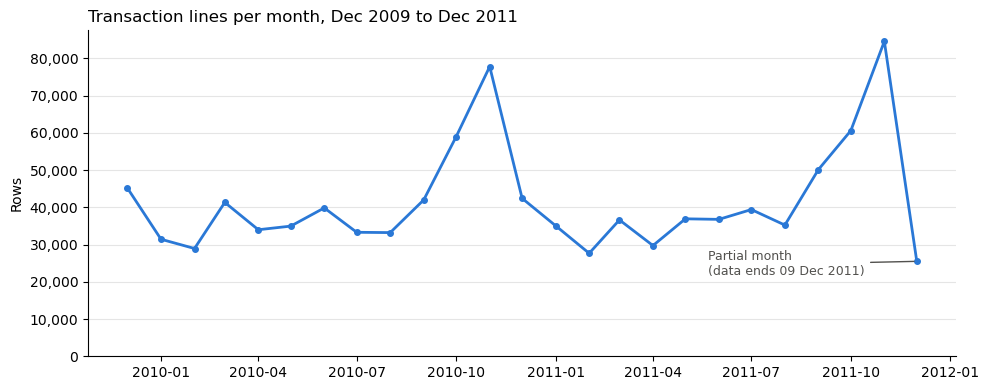

In [49]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Rows per month as a line chart, to see seasonality and any unusual months
monthly = d.dt.to_period("M").value_counts().sort_index()
x = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, monthly.values, color="#2a78d6", linewidth=2, marker="o", markersize=4)

# Mark the last month, which is only partly covered by the data
ax.annotate(f"Partial month\n(data ends {d.max():%d %b %Y})",
            xy=(x[-1], monthly.values[-1]), xytext=(-150, -10), textcoords="offset points",
            fontsize=9, color="#52514e", arrowprops=dict(arrowstyle="-", color="#52514e"))

ax.set_title("Transaction lines per month, Dec 2009 to Dec 2011", loc="left")
ax.set_ylabel("Rows")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylim(bottom=0)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Decision for InvoiceDate:** 

Correct date type, no missing values, and no missing months
(25 months from Dec 2009 to Dec 2011). 

Activity is clearly seasonal: it rises from September and peaks
in November each year, as wholesale customers stock up before Christmas. 

December 2011 is only partly
covered (data ends on 9 Dec 2011), so its lower count is not a real decline. No change is made.

## Price

Missing values, negative and zero prices, and overall distribution

In [50]:
p = transactions["Price"]
print("Data type:", p.dtype)
print("Missing:", p.isna().sum())
print("Negative:", (p < 0).sum())
print("Zero:", (p == 0).sum())
print()
print(p.describe().apply(lambda x: f"{x:,.2f}"))

Data type: float64
Missing: 0
Negative: 0
Zero: 2631

count    1,041,449.00
mean             4.75
std             91.82
min              0.00
25%              1.25
50%              2.10
75%              4.15
max         38,970.00
Name: Price, dtype: object


In [51]:
# Zero-price rows: which line types, and do they have a customer ID?
zero_price = transactions["Price"] == 0
print("Zero-price rows by line type:")
print(transactions.loc[zero_price, "line_type"].value_counts())
print()
print("...of which have a Customer ID:", transactions.loc[zero_price, "Customer ID"].notna().sum())
print("...of which are cancellations:", transactions.loc[zero_price, "is_cancellation"].sum())

Zero-price rows by line type:
line_type
product       2581
other           26
postage         17
adjustment       7
Name: count, dtype: int64

...of which have a Customer ID: 70
...of which are cancellations: 0


In [52]:
# For the 70 zero-price rows with a customer ID: are they on invoices that also have paid lines,
# or do some invoices consist only of zero-price lines (which would count as a purchase with no spending)?
cust_zero = transactions[zero_price & transactions["Customer ID"].notna()]
invoices = cust_zero["Invoice"].unique()

paid_on_same_invoice = (transactions[transactions["Invoice"].isin(invoices)]
                        .groupby("Invoice")["Price"].apply(lambda s: (s > 0).any()))

print("Invoices with zero-price rows (customer ID):", len(invoices))
print("...that also have paid lines:", paid_on_same_invoice.sum())
print("...that have only zero-price lines:", (~paid_on_same_invoice).sum())

Invoices with zero-price rows (customer ID): 61
...that also have paid lines: 55
...that have only zero-price lines: 6


In [53]:
# Highest prices: across all rows, and among product rows only
cols_to_show = ["Invoice", "StockCode", "Description", "Quantity", "Price", "Customer ID", "line_type"]
print("Highest prices, all rows:")
display(transactions.nlargest(10, "Price")[cols_to_show])
print("Highest prices, product rows only:")
display(transactions[transactions["line_type"] == "product"].nlargest(10, "Price")[cols_to_show])

Highest prices, all rows:


,Invoice,StockCode,Description,Quantity,Price,Customer ID,line_type
748142,C556445,M,Manual,-1,38970.00,15098.0,adjustment
241824,C512770,M,Manual,-1,25111.09,17399.0,adjustment
241827,512771,M,Manual,1,25111.09,NaN,adjustment
320581,C520667,BANK CHARGES,Bank Charges,-1,18910.69,NaN,other
1050063,C580605,AMAZONFEE,AMAZON FEE,-1,17836.46,NaN,other
569163,C540117,AMAZONFEE,AMAZON FEE,-1,16888.02,NaN,other
569164,C540118,AMAZONFEE,AMAZON FEE,-1,16453.71,NaN,other
517953,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33,NaN,other
517955,537632,AMAZONFEE,AMAZON FEE,1,13541.33,NaN,other
519294,C537651,AMAZONFEE,AMAZON FEE,-1,13541.33,NaN,other


Highest prices, product rows only:


,Invoice,StockCode,Description,Quantity,Price,Customer ID,line_type
192196,507637,84016,FLAG OF ST GEORGE CAR FLAG,1,1157.15,NaN,product
136403,502451,84016,FLAG OF ST GEORGE CAR FLAG,1,867.79,NaN,product
748132,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,15098.0,product
748143,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,649.50,15098.0,product
180997,506571,84016,FLAG OF ST GEORGE CAR FLAG,1,408.40,NaN,product
268525,515349,22656,VINTAGE BLUE KITCHEN CABINET,1,295.00,15513.0,product
268526,515349,22655,VINTAGE RED KITCHEN CABINET,1,295.00,15513.0,product
268766,515403,22655,VINTAGE RED KITCHEN CABINET,1,295.00,NaN,product
270553,515602,22656,VINTAGE BLUE KITCHEN CABINET,1,295.00,14895.0,product
272236,515811,22656,VINTAGE BLUE KITCHEN CABINET,1,295.00,15259.0,product


**Decision for Price:** 

No missing or negative prices. 2,631 rows have a price of 0; only 70 of them have
a customer ID, on 61 invoices, of which only 6 contain zero-price lines alone. The effect on purchase
counts is negligible.

The highest prices are non-product adjustments and fees, already classified by `line_type`.
Among products, a few car flags are priced at £400 to £1,157, which looks like an entry error,
but these rows have no customer ID. Customer 15098 bought 60 picnic baskets at £649.50 (£38,970)
and was refunded the same amount through a manual adjustment (M), which confirms that
`adjustment` rows must be included in customer value. No change is made.

### Customer ID
Check the format, convert to an integer type, and check whether missing IDs are concentrated in certain kinds of rows.

In [54]:
# Customer ID: data type, and the format of the non-missing values
c = transactions["Customer ID"]
c_known = c.dropna()

print("Data type:", c.dtype)
print("Rows with a Customer ID:", len(c_known), "| missing:", c.isna().sum())
print("Distinct customers:", c_known.nunique())
print("All whole numbers:", (c_known % 1 == 0).all())
print("Smallest:", c_known.min(), "| largest:", c_known.max())
print("Number of digits:")
print(c_known.astype("int64").astype(str).str.len().value_counts())

Data type: float64
Rows with a Customer ID: 809561 | missing: 231888
Distinct customers: 5942
All whole numbers: True
Smallest: 12346.0 | largest: 18287.0
Number of digits:
Customer ID
5    809561
Name: count, dtype: int64


In [55]:
# Does each invoice belong to exactly one customer?
per_invoice = transactions.groupby("Invoice")["Customer ID"].agg(
    ids="nunique",                                  # number of different customer IDs (missing not counted)
    missing=lambda s: s.isna().sum(),               # lines without an ID
    lines="size")

print("Invoices:", len(per_invoice))
print("Invoices with more than one customer ID:", (per_invoice["ids"] > 1).sum())
print("Invoices with an ID on some lines but missing on others:",
      ((per_invoice["ids"] == 1) & (per_invoice["missing"] > 0)).sum())
print("Invoices with no ID on any line:", (per_invoice["ids"] == 0).sum())

Invoices: 50229
Invoices with more than one customer ID: 0
Invoices with an ID on some lines but missing on others: 0
Invoices with no ID on any line: 5353


In [56]:
# Missing Customer ID: share of rows, and share of net value (product + adjustment rows)
no_id = transactions["Customer ID"].isna()
value = transactions["Quantity"] * transactions["Price"]
counts_for_value = transactions["line_type"].isin(["product", "adjustment"])

print("Rows without a Customer ID:", no_id.sum(), f"({no_id.mean():.1%} of rows)")
print("Net value without a Customer ID:",
      f"{value[no_id & counts_for_value].sum():,.2f}",
      f"({value[no_id & counts_for_value].sum() / value[counts_for_value].sum():.1%} of net value)")
print()
print("Rows without a Customer ID, by line type:")
print(transactions.loc[no_id, "line_type"].value_counts())
print()
print("Cancellations without a Customer ID:", (no_id & transactions["is_cancellation"]).sum(),
      "of", transactions["is_cancellation"].sum())

Rows without a Customer ID: 231888 (22.3% of rows)
Net value without a Customer ID: 2,676,459.51 (14.2% of net value)

Rows without a Customer ID, by line type:
line_type
product       229735
postage         1535
adjustment       316
other            302
Name: count, dtype: int64

Cancellations without a Customer ID: 719 of 19165


In [57]:
# Are rows without a Customer ID different from rows with one? (product rows only)
prod = transactions[transactions["line_type"] == "product"]
has_id = prod["Customer ID"].notna().map({True: "With ID", False: "Without ID"})

comparison = prod.groupby(has_id).agg(
    Rows=("Invoice", "size"),
    Median_price=("Price", "median"),
    Median_quantity=("Quantity", "median"),
    Share_UK=("Country", lambda s: (s == "United Kingdom").mean()),
)
comparison["Share_UK"] = comparison["Share_UK"].map("{:.1%}".format)
display(comparison)

# Share of product rows without an ID, by month: is the missing share stable over time?
missing_by_month = prod["Customer ID"].isna().groupby(prod["InvoiceDate"].dt.to_period("M")).mean()
print(missing_by_month.map("{:.1%}".format))

,Rows,Median_price,Median_quantity,Share_UK
Customer ID,,,,
With ID,805890,1.95,5.0,90.1%
Without ID,229735,3.29,1.0,98.7%


InvoiceDate
2009-12    29.6%
2010-01    28.6%
2010-02    17.3%
2010-03    19.7%
2010-04    17.9%
2010-05    15.1%
2010-06    19.7%
2010-07    16.5%
2010-08    18.7%
2010-09    15.6%
2010-10    14.1%
2010-11    20.9%
2010-12    36.7%
2011-01    37.5%
2011-02    26.2%
2011-03    23.9%
2011-04    21.9%
2011-05    21.6%
2011-06    24.1%
2011-07    30.1%
2011-08    21.4%
2011-09    18.5%
2011-10    16.3%
2011-11    22.5%
2011-12    30.8%
Freq: M, Name: Customer ID, dtype: object


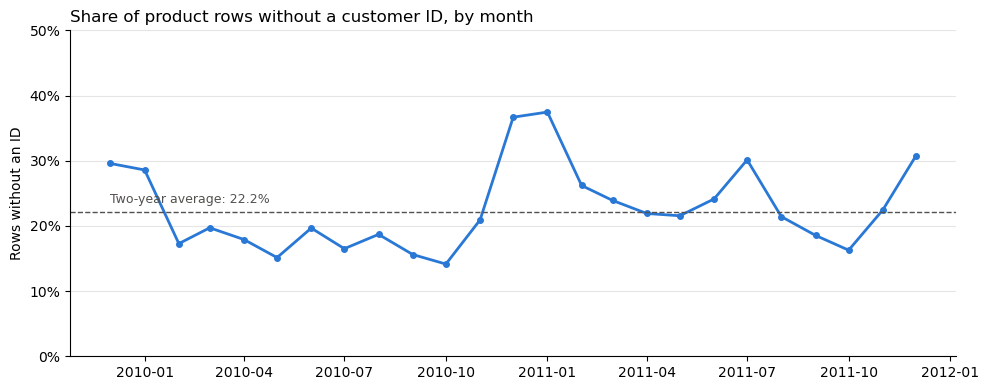

In [58]:
# Share of product rows without a Customer ID, by month
x = missing_by_month.index.to_timestamp()
overall = prod["Customer ID"].isna().mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, missing_by_month.values, color="#2a78d6", linewidth=2, marker="o", markersize=4)
ax.axhline(overall, color="#52514e", linewidth=1, linestyle="--")
ax.annotate(f"Two-year average: {overall:.1%}", xy=(x[0], overall), xytext=(0, 6),
            textcoords="offset points", fontsize=9, color="#52514e")

ax.set_title("Share of product rows without a customer ID, by month", loc="left")
ax.set_ylabel("Rows without an ID")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set_ylim(0, 0.5)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [59]:
# Is the July 2011 peak caused by more rows without an ID, or fewer rows with one?
month = prod["InvoiceDate"].dt.to_period("M")
counts = pd.crosstab(month, prod["Customer ID"].isna().map({True: "Without ID", False: "With ID"}))
counts.loc["2011-05":"2011-09"]

Customer ID,With ID,Without ID
InvoiceDate,,
2011-05,28761,7902
2011-06,27708,8812
2011-07,27359,11797
2011-08,27519,7502
2011-09,40627,9248


In [60]:
transactions["Customer ID"] = transactions["Customer ID"].astype("Int64")

**22.3% of rows (14.2% of net value) have no customer ID.**

These rows look like retail sales:
  higher prices (median £3.29 vs £1.95), single units (median 1 vs 5), almost all in the UK,
  and rarely cancelled (719 of 19,165 cancellations). 
  
The share without an ID ranges from 14% to 38%
  by month, with no lasting change. The one-month rise in July 2011 comes from more rows without an ID
  (11,797 vs about 7,500 to 8,800 in nearby months) while rows with an ID stayed stable.

The customer-level analysis therefore describes identified (mostly wholesale) customers,
  covering 85.8% of net value.

In [61]:
# Is each customer always recorded in the same country?
countries_per_customer = transactions.dropna(subset=["Customer ID"]).groupby("Customer ID")["Country"].nunique()

print("Customers:", len(countries_per_customer))
print("Customers recorded in more than one country:", (countries_per_customer > 1).sum())

# Show those customers and the countries they appear in, with row counts
multi_country = countries_per_customer[countries_per_customer > 1].index
(transactions[transactions["Customer ID"].isin(multi_country)]
 .groupby(["Customer ID", "Country"]).size()
 .rename("Rows"))

Customers: 5942
Customers recorded in more than one country: 13


Customer ID  Country       
12370        Austria            43
             Cyprus            159
12394        Belgium            21
             Denmark             6
12413        France             40
             Spain              13
12417        Belgium           347
             Spain              34
12422        Australia          61
             Switzerland       115
12423        Belgium           153
             Denmark            13
12429        Austria            21
             Denmark           133
12431        Australia         256
             Belgium           143
12449        Belgium           191
             Denmark            10
12455        Cyprus            179
             Spain              48
12457        Cyprus              3
             Switzerland        90
12652        France             51
             Germany             3
12745        EIRE                1
             United Kingdom     22
Name: Rows, dtype: int64

**13 of 5,942 customers (0.2%) appear in more than one country.**

This is too few to affect the results, so **each Customer ID is treated as one customer**. 

Country is not used in the research questions;
  if needed, each customer's most frequent country can be used.
  
No change is made.

## Country: 

Every distinct value with its row count and number of customers, sorted alphabetically, so abbreviations, spelling variants and unclear values are easy to spot

In [62]:
country = transactions["Country"]
print("Distinct countries:", country.nunique())
print("Values with leading/trailing spaces:", (country != country.str.strip()).sum())
print("Distinct values that differ only by case:",
      country.nunique() - country.str.lower().nunique())

(transactions.groupby("Country")
 .agg(Rows=("Invoice", "size"), Customers=("Customer ID", "nunique"))
 .sort_index())

Distinct countries: 43
Values with leading/trailing spaces: 0
Distinct values that differ only by case: 0


,Rows,Customers
Country,,
Australia,1891,15
Austria,938,13
Bahrain,126,2
Belgium,3111,29
Bermuda,34,0
Brazil,94,2
Canada,228,5
Channel Islands,1647,14
Cyprus,1176,11


**Decision for Country:** 

43 values, with no spacing, case or spelling variants. 

A few values are not
specific countries (European Community, West Indies, Unspecified: under 1,000 rows in total) and some use
short forms (EIRE, RSA, USA), but each appears in only one form. 

Country is not used in the research
questions, so no change is made. 

The UK accounts for 5,410 of 5,942 customers.

## Final checks

In [63]:
# 1. Structure of the final table
print("Rows:", len(transactions), "| Columns:", transactions.shape[1])
print(transactions.dtypes)
print()

# 2. The cleaning log reconciles with the raw data and the final table
log = pd.DataFrame(cleaning_log)
display(log)
raw_total = sum(len(df) for df in sheets.values())
assert log["Rows remaining"].iloc[0] == raw_total, "Log does not start from the raw row count"
assert log["Rows remaining"].iloc[-1] == len(transactions), "Log does not end at the final row count"
assert log["Rows removed"].sum() == raw_total - len(transactions), "Removed rows do not add up"

# 3. Earlier cleaning results still hold
assert not transactions["Invoice"].str.startswith("A").any(), "A invoices remain"
# Every negative quantity is a cancellation
assert ((transactions["Quantity"] < 0) <= transactions["is_cancellation"]).all(), "A negative quantity is not a cancellation"
# Every product cancellation has a negative quantity (one non-product manual adjustment, C496350, is the only exception)
assert not (transactions["is_cancellation"] & (transactions["Quantity"] >= 0) & transactions["is_product"]).any(), \
    "A product cancellation has a non-negative quantity"
assert (transactions["Price"] >= 0).all(), "Negative prices remain"
assert transactions["Customer ID"].dtype == "Int64", "Customer ID is not an integer type"

# 4. Flag columns are complete and consistent
flag_cols = ["is_exact_duplicate", "is_cancellation", "is_product", "line_type"]
assert transactions[flag_cols].notna().all().all(), "A flag column has missing values"
assert set(transactions["line_type"]) == {"product", "adjustment", "postage", "other"}, "Unexpected line_type values"
assert ((transactions["line_type"] == "product") == transactions["is_product"]).all(), "line_type and is_product disagree"

# 5. The duplicate flag still marks exactly the extra copies within the final table
assert (transactions["is_exact_duplicate"] == transactions.duplicated(subset=data_cols, keep="first")).all(), \
    "Duplicate flag no longer matches the final table"

print("All final checks passed.")
print()
print("Flag summary:")
print(transactions[["is_exact_duplicate", "is_cancellation", "is_product"]].sum())
print(transactions["line_type"].value_counts())

Rows: 1041449 | Columns: 13
Invoice                       object
StockCode                     object
Description           string[python]
Quantity                       int64
InvoiceDate           datetime64[ns]
Price                        float64
Customer ID                    Int64
Country                       object
Sheet                         object
is_exact_duplicate              bool
is_cancellation                 bool
is_product                      bool
line_type                     object
dtype: object



,Step,Rows removed,Rows remaining
0,Combine the two sheets,0,1067371
1,Remove the duplicated overlap period (later sh...,22523,1044848
2,Remove bad-debt adjustments (A invoices),6,1044842
3,"Remove stock adjustments (negative quantity, n...",3393,1041449


All final checks passed.

Flag summary:
is_exact_duplicate      11812
is_cancellation         19165
is_product            1035625
dtype: int64
line_type
product       1035625
postage          3788
adjustment       1646
other             390
Name: count, dtype: int64


## Save the cleaned data

In [64]:
# Save the cleaned table for the rest of the analysis, plus the cleaning log for the report
os.makedirs("data/clean", exist_ok=True)
CLEAN_FILE = "data/clean/transactions_clean.parquet"
LOG_FILE = "data/clean/cleaning_log.csv"

transactions.to_parquet(CLEAN_FILE, index=False)
pd.DataFrame(cleaning_log).to_csv(LOG_FILE, index=False)

# Check: reading the file back gives exactly the same table (values and data types)
reloaded = pd.read_parquet(CLEAN_FILE)
pd.testing.assert_frame_equal(reloaded, transactions.reset_index(drop=True))
print("Saved", len(reloaded), "rows and", reloaded.shape[1], "columns to", CLEAN_FILE)
print("Saved the cleaning log to", LOG_FILE)

Saved 1041449 rows and 13 columns to data/clean/transactions_clean.parquet
Saved the cleaning log to data/clean/cleaning_log.csv


## Notes for the team

**File:** `data/clean/transactions_clean.parquet` (1,041,449 rows, one row per product line on an invoice).
Read it with `pd.read_parquet("data/clean/transactions_clean.parquet")`.

**Columns added during cleaning**

| Column | Meaning |
|---|---|
| `Sheet` | Which sheet of the original Excel file the row came from |
| `is_exact_duplicate` | True for extra copies of a row that is identical in all 8 original columns (11,812 rows). Kept; likely genuine repeated scans |
| `is_cancellation` | True for invoices starting with "C" (19,165 rows), including manual refunds (M) |
| `is_product` | True for goods; False for postage, adjustments, fees, samples, tests and gift vouchers |
| `line_type` | `product`, `adjustment` (M, D, ADJUST: refunds, manual charges, discounts), `postage` (POST, DOT, C2) or `other` |

**Which rows to use**

| Analysis | Rows |
|---|---|
| Customer-level analysis (RFM, segments, lapse model, contact list) | `Customer ID` not missing |
| Customer value (net spend) | `line_type` in `product` or `adjustment`, sales and cancellations together |
| Product-level analysis (top products, cancellations by product) | `line_type == "product"` |
| Cancellations | `is_cancellation == True` |
| Robustness check | Repeat key results without `is_exact_duplicate` rows |

**Things to keep in mind**
- Value of a line = `Quantity * Price`. Cancellations have negative quantities, so summing gives net value.
- 22.3% of rows (14.2% of net value) have no customer ID. They look like retail sales, so customer-level
  results describe identified (mostly wholesale) customers.
- Data ends on 9 Dec 2011, so December 2011 is incomplete. Activity is strongly seasonal (peak in November).
- The two largest purchases (invoices 581483 and 541431) were each fully cancelled within about 15 minutes.
  They may dominate cancellation totals.
- Customer 15098 bought £38,970 of picnic baskets and was refunded the same amount through a manual
  adjustment (M), which is why customer value must include `adjustment` rows.
- Postage is not counted in customer value by default. Confirm this choice as a group.